In [1]:
!pip install biosppy pyhrv --quiet

In [2]:
import os
import glob
import zipfile
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import butter, filtfilt, iirnotch, find_peaks
from scipy.stats import skew, kurtosis

from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
ZIP_PATH = "/content/drive/MyDrive/toliet-single-lead-thigh-based-electrocardiography-using-polimeric-dry-electrodes-1.0.1.zip"
EXTRACT_DIR = "/content/toliet"

os.makedirs(EXTRACT_DIR, exist_ok=True)

print("ZIP açılıyor...")
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

print("Tamamlandı.")

ZIP açılıyor...
Tamamlandı.


In [5]:
# Açılan ana klasörü bul
subfolders = os.listdir(EXTRACT_DIR)
print("Açılan klasörler:", subfolders)

Açılan klasörler: ['toliet-single-lead-thigh-based-electrocardiography-using-polimeric-dry-electrodes-1.0.1']


In [6]:
DATA_ROOT = os.path.join(
    EXTRACT_DIR,
    "toliet-single-lead-thigh-based-electrocardiography-using-polimeric-dry-electrodes-1.0.1"
)

EXP_DIR = os.path.join(DATA_ROOT, "ECG_EXP")
REF_DIR = os.path.join(DATA_ROOT, "ECG_REF")

print("DATA_ROOT:", DATA_ROOT)
print("EXP_DIR:", EXP_DIR)
print("REF_DIR:", REF_DIR)

DATA_ROOT: /content/toliet/toliet-single-lead-thigh-based-electrocardiography-using-polimeric-dry-electrodes-1.0.1
EXP_DIR: /content/toliet/toliet-single-lead-thigh-based-electrocardiography-using-polimeric-dry-electrodes-1.0.1/ECG_EXP
REF_DIR: /content/toliet/toliet-single-lead-thigh-based-electrocardiography-using-polimeric-dry-electrodes-1.0.1/ECG_REF


In [7]:
metadata = pd.read_csv(os.path.join(DATA_ROOT, "DataSet.csv"))
print(metadata.head())
print("Metadata boyutu:", metadata.shape)
print("Sütunlar:", list(metadata.columns))

  ID;Age;Weight ;Height;Gender;Observations field;;;;;;;;;;;;;;;;
0                  1;40;77;170;Male;;;;;;;;;;;;;;;;;             
1                  2;41;78;171;Male;;;;;;;;;;;;;;;;;             
2                  3;38;79;173;Male;;;;;;;;;;;;;;;;;             
3                  4;36;81;171;Male;;;;;;;;;;;;;;;;;             
4                  5;36;60;171;Male;;;;;;;;;;;;;;;;;             
Metadata boyutu: (149, 1)
Sütunlar: ['ID;Age;Weight ;Height;Gender;Observations field;;;;;;;;;;;;;;;;']


In [8]:
exp_files = sorted(glob.glob(os.path.join(EXP_DIR, "*.txt")))
print("ECG_EXP dosya sayısı:", len(exp_files))

for f in exp_files[:5]:
    print(os.path.basename(f))

ECG_EXP dosya sayısı: 145
1.txt
10.txt
11.txt
12.txt
13.txt


In [9]:
# ================================
# PART 4 — ECG Preprocessing Fonksiyonları (DÜZELTİLMİŞ)
# ================================

FS = 1000
CHANNELS = ["A1", "A2", "A3", "A4"]

def bandpass_filter(signal, fs=1000, low=0.5, high=40, order=4):
    signal = np.asarray(signal, dtype=float)
    nyq = 0.5 * fs
    low = low / nyq
    high = high / nyq
    b, a = butter(order, [low, high], btype="band")
    return filtfilt(b, a, signal)

def notch_filter(signal, fs=1000, f0=50.0, q=30):
    signal = np.asarray(signal, dtype=float)
    w0 = f0 / (fs / 2)
    b, a = iirnotch(w0, q)
    return filtfilt(b, a, signal)

def preprocess_ecg(raw_signal, fs=1000):
    sig = np.asarray(raw_signal, dtype=float)

    # NaN varsa temizle
    sig = np.nan_to_num(sig)

    # Ortalama çıkar
    sig = sig - np.mean(sig)

    # Önce notch, sonra bandpass
    sig = notch_filter(sig, fs=fs, f0=50.0, q=30)
    sig = bandpass_filter(sig, fs=fs, low=0.5, high=40, order=4)

    return sig

In [10]:
# ================================
# PART 5 — Kayıtları Yükle ve Preprocess Et (DÜZELTİLMİŞ)
# ================================

def load_and_preprocess(filepath, fs=1000):
    df = pd.read_csv(filepath, sep="\t", comment="#", header=None)

    col_names = ['nSeq','I1','I2','O1','O2','A1','A2','A3','A4','A5','A6','A7']
    df.columns = col_names[:df.shape[1]]

    raw_signals = {}
    signals = {}
    aktif = []

    for ch in CHANNELS:
        if ch in df.columns:
            raw = df[ch].values.astype(float)

            if np.std(raw) < 1e-6:
                continue

            try:
                proc = preprocess_ecg(raw, fs=fs)
                raw_signals[ch] = raw
                signals[ch] = proc
                aktif.append(ch)
            except Exception as e:
                print(f"Hata ({os.path.basename(filepath)} - {ch}): {e}")

    return {
        "id": os.path.basename(filepath).replace(".txt", ""),
        "filepath": filepath,
        "raw_signals": raw_signals,
        "signals": signals,
        "aktif": aktif
    }


exp_files = sorted(glob.glob(os.path.join(EXP_DIR, "*.txt")))
print("Bulunan ECG_EXP dosya sayısı:", len(exp_files))

all_processed = []

for f in exp_files:
    try:
        rec = load_and_preprocess(f, fs=FS)
        if len(rec["aktif"]) > 0:
            all_processed.append(rec)
        else:
            print(f"Aktif kanal yok: {os.path.basename(f)}")
    except Exception as e:
        print(f"Dosya okunamadı: {os.path.basename(f)} -> {e}")

print("\nToplam işlenen kayıt sayısı:", len(all_processed))

for rec in all_processed[:3]:
    print(f"Kayıt ID: {rec['id']}, Aktif kanallar: {rec['aktif']}")

Bulunan ECG_EXP dosya sayısı: 145

Toplam işlenen kayıt sayısı: 145
Kayıt ID: 1, Aktif kanallar: ['A1', 'A2', 'A4']
Kayıt ID: 10, Aktif kanallar: ['A1', 'A2', 'A3', 'A4']
Kayıt ID: 11, Aktif kanallar: ['A2']


Kayıt ID: 1
Aktif kanallar: ['A1', 'A2', 'A4']


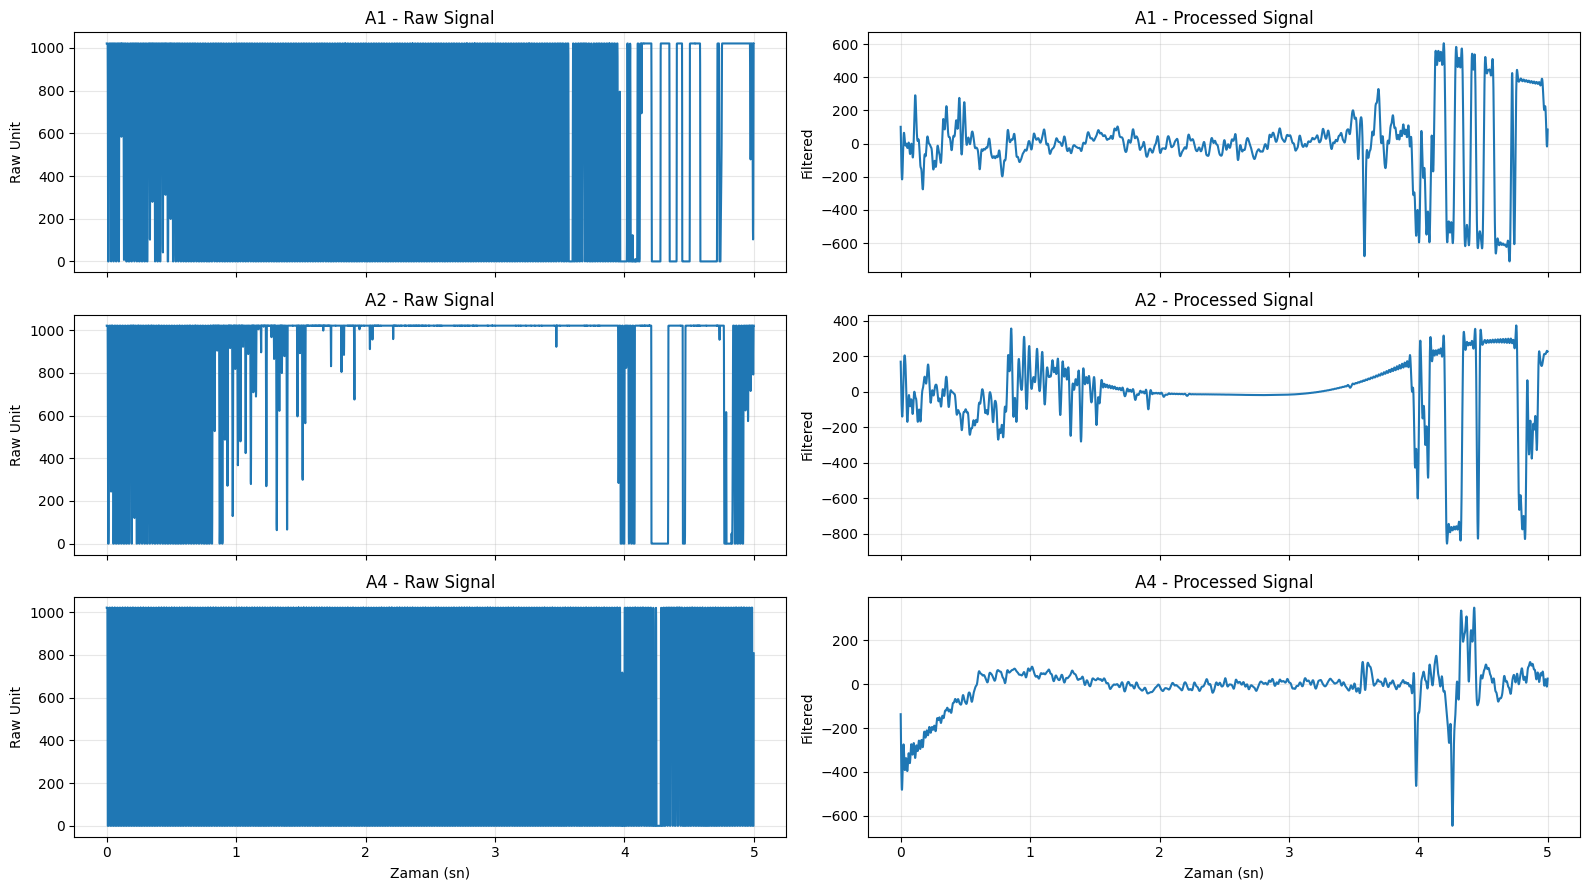

In [11]:
# ================================
# PART 6 — Raw vs Processed Karşılaştırma
# ================================

test_rec = all_processed[0]

print("Kayıt ID:", test_rec["id"])
print("Aktif kanallar:", test_rec["aktif"])

plot_channels = test_rec["aktif"]
N = min(5 * FS, min(len(test_rec["signals"][ch]) for ch in plot_channels))
t = np.arange(N) / FS

fig, axes = plt.subplots(len(plot_channels), 2, figsize=(16, 3*len(plot_channels)), sharex=True)

if len(plot_channels) == 1:
    axes = np.array([axes])

for i, ch in enumerate(plot_channels):
    raw_sig = test_rec["raw_signals"][ch][:N]
    proc_sig = test_rec["signals"][ch][:N]

    axes[i, 0].plot(t, raw_sig)
    axes[i, 0].set_title(f"{ch} - Raw Signal")
    axes[i, 0].set_ylabel("Raw Unit")
    axes[i, 0].grid(alpha=0.3)

    axes[i, 1].plot(t, proc_sig)
    axes[i, 1].set_title(f"{ch} - Processed Signal")
    axes[i, 1].set_ylabel("Filtered")
    axes[i, 1].grid(alpha=0.3)

axes[-1, 0].set_xlabel("Zaman (sn)")
axes[-1, 1].set_xlabel("Zaman (sn)")
plt.tight_layout()
plt.show()

In [12]:
# ================================
# PART 7 — R-Peak Detection (DAHA SIKI)
# ================================

def detect_rpeaks(signal, fs=1000):
    sig = np.asarray(signal, dtype=float)

    if np.std(sig) < 1e-6:
        return np.array([]), np.array([])

    low_clip = np.percentile(sig, 1)
    high_clip = np.percentile(sig, 99)
    sig_clip = np.clip(sig, low_clip, high_clip)

    sig_std = np.std(sig_clip)

    peak_height = sig_std * 1.5
    peak_prominence = sig_std * 0.8
    peak_distance = int(0.7 * fs)

    peaks, properties = find_peaks(
        sig_clip,
        height=peak_height,
        distance=peak_distance,
        prominence=peak_prominence
    )

    if len(peaks) > 1:
        rr_intervals = np.diff(peaks) / fs * 1000.0
    else:
        rr_intervals = np.array([])

    return peaks, rr_intervals


for rec in all_processed:
    rec["peaks"] = {}
    rec["rr"] = {}

    for ch in rec["aktif"]:
        sig = rec["signals"][ch]
        peaks, rr = detect_rpeaks(sig, fs=FS)
        rec["peaks"][ch] = peaks
        rec["rr"][ch] = rr

print("R-peak detection tamamlandı.")

test_rec = all_processed[0]
print("Kayıt ID:", test_rec["id"])

for ch in test_rec["aktif"]:
    print(f"{ch} -> peak sayısı: {len(test_rec['peaks'][ch])}")

R-peak detection tamamlandı.
Kayıt ID: 1
A1 -> peak sayısı: 15
A2 -> peak sayısı: 8
A4 -> peak sayısı: 10


In [13]:
# ================================
# PART 8 — SNR Hesaplama
# ================================

def compute_snr(signal, peaks, fs=1000, qrs_ms=100):
    """
    Peak çevresini 'signal', geri kalan kısmı 'noise' kabul ederek
    yaklaşık SNR hesabı yapar.
    """
    if len(peaks) < 2:
        return np.nan

    half_win = int((qrs_ms / 1000.0) * fs / 2)

    signal_mask = np.zeros(len(signal), dtype=bool)

    for p in peaks:
        start = max(0, p - half_win)
        end = min(len(signal), p + half_win)
        signal_mask[start:end] = True

    noise_mask = ~signal_mask

    signal_part = signal[signal_mask]
    noise_part = signal[noise_mask]

    if len(signal_part) < 10 or len(noise_part) < 10:
        return np.nan

    signal_power = np.mean(signal_part ** 2)
    noise_power = np.mean(noise_part ** 2)

    if noise_power <= 0:
        return np.nan

    snr_db = 10 * np.log10(signal_power / noise_power)
    return snr_db


# ================================
# Tüm kayıtlarda kanal bazlı SNR hesapla
# ================================

for rec in all_processed:
    rec["snr"] = {}

    for ch in rec["aktif"]:
        sig = rec["signals"][ch]
        peaks = rec["peaks"][ch]

        snr_db = compute_snr(sig, peaks, fs=FS)
        rec["snr"][ch] = snr_db

print("SNR hesaplandı.")


# ================================
# Küçük kontrol
# ================================

test_rec = all_processed[0]
print("Kayıt ID:", test_rec["id"])

for ch in test_rec["aktif"]:
    print(f"{ch} -> SNR: {test_rec['snr'][ch]}")

SNR hesaplandı.
Kayıt ID: 1
A1 -> SNR: 7.42681645784483
A2 -> SNR: 8.84624692707201
A4 -> SNR: 12.512561727470635


In [14]:
# ================================
# PART 9 + 10 + 11 — Dataset Builder (DÜZELTİLMİŞ)
# ================================

# Segment ayarları
WINDOW_SEC = 2
STEP_SEC = 1

WINDOW = int(WINDOW_SEC * FS)
STEP = int(STEP_SEC * FS)

# SNR threshold biraz gevşetildi
SNR_THRESHOLD_DB = 3.0


def parse_subject_id(record_id):
    """
    Şimdilik record_id'yi subject_id gibi kullanıyoruz.
    Gerekirse sonra revize ederiz.
    """
    return str(record_id)


def is_saturated(segment, low=5, high=1018, ratio_thresh=0.50):
    """
    Raw segment içinde ADC saturasyonunu kontrol eder.
    Segmentin %50'den fazlası 0 veya 1023 civarındaysa poor kabul edilir.
    """
    seg = np.asarray(segment)
    sat_low = np.sum(seg <= low)
    sat_high = np.sum(seg >= high)
    sat_ratio = (sat_low + sat_high) / len(seg)
    return sat_ratio > ratio_thresh


def extract_features(segment, local_peaks, fs=1000):
    """
    Segmentten istatistiksel ve RR-tabanlı feature çıkarır.
    """
    segment = np.asarray(segment, dtype=float)

    feats = {}

    # Temel istatistiksel özellikler
    feats["mean"] = np.mean(segment)
    feats["std"] = np.std(segment)
    feats["rms"] = np.sqrt(np.mean(segment ** 2))
    feats["min"] = np.min(segment)
    feats["max"] = np.max(segment)
    feats["ptp"] = np.ptp(segment)
    feats["skew"] = skew(segment)
    feats["kurtosis"] = kurtosis(segment)

    # Basit sinyal özellikleri
    feats["zero_crossings"] = np.sum(np.diff(np.signbit(segment)).astype(int))
    feats["energy"] = np.sum(segment ** 2) / len(segment)

    # Peak / RR özellikleri
    feats["num_peaks"] = len(local_peaks)

    if len(local_peaks) > 1:
        rr = np.diff(local_peaks) / fs * 1000.0  # ms
        feats["rr_mean"] = np.mean(rr)
        feats["rr_std"] = np.std(rr)
        feats["rr_min"] = np.min(rr)
        feats["rr_max"] = np.max(rr)

        diff_rr = np.diff(rr)
        feats["rmssd"] = np.sqrt(np.mean(diff_rr ** 2)) if len(diff_rr) > 0 else np.nan
    else:
        feats["rr_mean"] = np.nan
        feats["rr_std"] = np.nan
        feats["rr_min"] = np.nan
        feats["rr_max"] = np.nan
        feats["rmssd"] = np.nan

    return feats


# Dataset oluşturma
rows = []

for rec in all_processed:
    record_id = rec["id"]
    subject_id = parse_subject_id(record_id)

    for ch in rec["aktif"]:
        sig = rec["signals"][ch]
        raw_sig = rec["raw_signals"][ch]
        peaks = rec["peaks"][ch]

        if len(sig) < WINDOW:
            continue

        for start in range(0, len(sig) - WINDOW + 1, STEP):
            end = start + WINDOW

            seg = sig[start:end]
            raw_seg = raw_sig[start:end]

            # Segment içindeki peakler
            local_peaks = peaks[(peaks >= start) & (peaks < end)] - start

            # Segment SNR
            snr_db = compute_snr(seg, local_peaks, fs=FS)

            # Saturation kontrolü
            saturated_flag = int(is_saturated(raw_seg))

            # Label üretimi
            if saturated_flag == 1:
                label = 0   # poor
            else:
                if np.isnan(snr_db):
                    continue
                label = 1 if snr_db >= SNR_THRESHOLD_DB else 0

            # Feature çıkar
            feats = extract_features(seg, local_peaks, fs=FS)

            row = {
                "record_id": record_id,
                "subject_id": subject_id,
                "channel": ch,
                "start_idx": start,
                "end_idx": end,
                "snr_db": snr_db,
                "saturated": saturated_flag,
                "label": label
            }

            row.update(feats)
            rows.append(row)

dataset_df = pd.DataFrame(rows)

print("Dataset boyutu:", dataset_df.shape)
print(dataset_df.head())

print("\nLabel dağılımı:")
print(dataset_df["label"].value_counts())

print("\nLabel oranı:")
print(dataset_df["label"].value_counts(normalize=True))

Dataset boyutu: (22977, 24)
  record_id subject_id channel  start_idx  end_idx    snr_db  saturated  \
0         1          1      A1          0     2000       NaN          1   
1         1          1      A1       1000     3000       NaN          1   
2         1          1      A1       2000     4000       NaN          1   
3         1          1      A1       3000     5000       NaN          1   
4         1          1      A1       4000     6000 -0.311647          1   

   label      mean         std  ...      skew   kurtosis  zero_crossings  \
0      0 -0.859256   73.690516  ...  0.275117   2.348392              43   
1      0  1.061734   41.073945  ...  0.050020  -0.680063              33   
2      0  1.661344  104.841918  ... -2.386349  12.470968              32   
3      0  9.031995  335.176377  ... -0.438067  -0.599916              32   
4      0  8.574878  455.841033  ... -0.387407  -1.588834              28   

          energy  num_peaks  rr_mean  rr_std  rr_min  rr_max  rm

Dataset boyutu: (22977, 24)

Kolonlar:
['record_id', 'subject_id', 'channel', 'start_idx', 'end_idx', 'snr_db', 'saturated', 'label', 'mean', 'std', 'rms', 'min', 'max', 'ptp', 'skew', 'kurtosis', 'zero_crossings', 'energy', 'num_peaks', 'rr_mean', 'rr_std', 'rr_min', 'rr_max', 'rmssd']

İlk 5 satır:


,record_id,subject_id,channel,start_idx,end_idx,snr_db,saturated,label,mean,std,...,skew,kurtosis,zero_crossings,energy,num_peaks,rr_mean,rr_std,rr_min,rr_max,rmssd
0,1,1,A1,0,2000,NaN,1,0,-0.859256,73.690516,...,0.275117,2.348392,43,5431.030497,1,NaN,NaN,NaN,NaN,NaN
1,1,1,A1,1000,3000,NaN,1,0,1.061734,41.073945,...,0.050020,-0.680063,33,1688.196205,0,NaN,NaN,NaN,NaN,NaN
2,1,1,A1,2000,4000,NaN,1,0,1.661344,104.841918,...,-2.386349,12.470968,32,10994.587867,0,NaN,NaN,NaN,NaN,NaN
3,1,1,A1,3000,5000,NaN,1,0,9.031995,335.176377,...,-0.438067,-0.599916,32,112424.780514,1,NaN,NaN,NaN,NaN,NaN
4,1,1,A1,4000,6000,-0.311647,1,0,8.574878,455.841033,...,-0.387407,-1.588834,28,207864.575479,2,1577.0,0.0,1577.0,1577.0,NaN



Label dağılımı:
label
0    20933
1     2044
Name: count, dtype: int64

Label oranı:
label
0    0.911041
1    0.088959
Name: proportion, dtype: float64


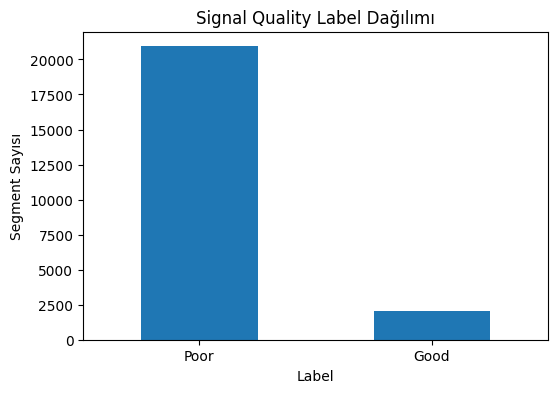

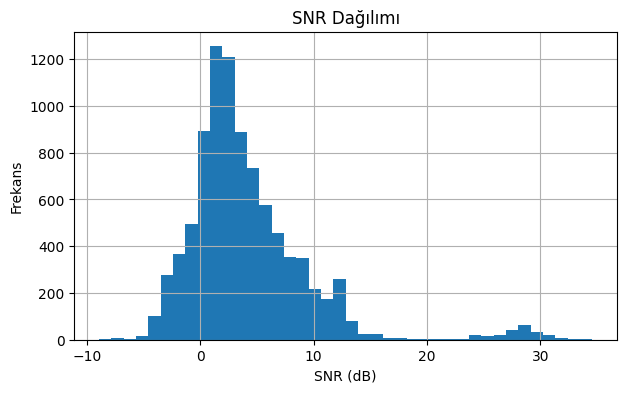


Kanal bazlı label dağılımı:
label_name  Good   Poor
channel                
A1           926   1180
A2           485   4118
A3           116  11986
A4           517   3649


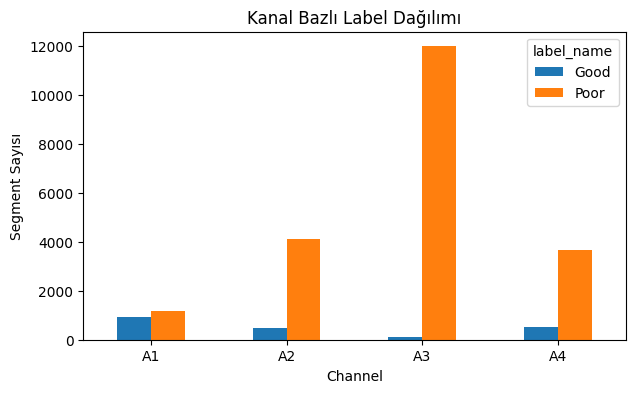


Kanal bazlı ortalama SNR:
channel
A4    7.087310
A3    4.941397
A1    3.380743
A2    2.723613
Name: snr_db, dtype: float64


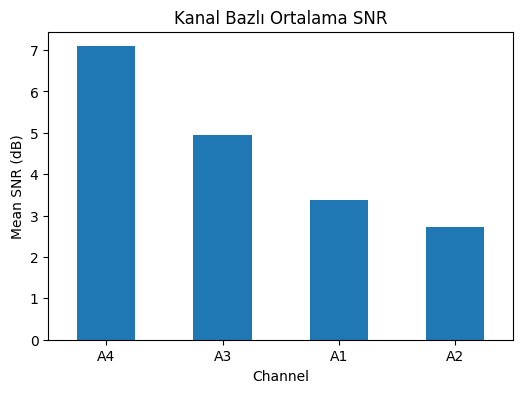

In [15]:
# ================================
# PART 12 — Label Dağılımı ve Temel Kontroller
# ================================

print("Dataset boyutu:", dataset_df.shape)
print("\nKolonlar:")
print(dataset_df.columns.tolist())

print("\nİlk 5 satır:")
display(dataset_df.head())

print("\nLabel dağılımı:")
print(dataset_df["label"].value_counts())

print("\nLabel oranı:")
print(dataset_df["label"].value_counts(normalize=True))


# Label isimleri
dataset_df["label_name"] = dataset_df["label"].map({0: "Poor", 1: "Good"})

# Label dağılım grafiği
plt.figure(figsize=(6,4))
dataset_df["label_name"].value_counts().plot(kind="bar")
plt.title("Signal Quality Label Dağılımı")
plt.xlabel("Label")
plt.ylabel("Segment Sayısı")
plt.xticks(rotation=0)
plt.show()


# SNR dağılımı (NaN olmayanlar)
plt.figure(figsize=(7,4))
dataset_df["snr_db"].dropna().hist(bins=40)
plt.title("SNR Dağılımı")
plt.xlabel("SNR (dB)")
plt.ylabel("Frekans")
plt.show()


# Kanal bazlı label dağılımı
channel_label_summary = pd.crosstab(dataset_df["channel"], dataset_df["label_name"])
print("\nKanal bazlı label dağılımı:")
print(channel_label_summary)

channel_label_summary.plot(kind="bar", figsize=(7,4))
plt.title("Kanal Bazlı Label Dağılımı")
plt.xlabel("Channel")
plt.ylabel("Segment Sayısı")
plt.xticks(rotation=0)
plt.show()


# Kanal bazlı ortalama SNR
channel_snr_summary = dataset_df.groupby("channel")["snr_db"].mean().sort_values(ascending=False)
print("\nKanal bazlı ortalama SNR:")
print(channel_snr_summary)

plt.figure(figsize=(6,4))
channel_snr_summary.plot(kind="bar")
plt.title("Kanal Bazlı Ortalama SNR")
plt.xlabel("Channel")
plt.ylabel("Mean SNR (dB)")
plt.xticks(rotation=0)
plt.show()

In [16]:
# ================================
# PART 13 — X, y, groups Hazırlama
# ================================

# Modelde kullanılacak feature sütunları
feature_cols = [
    "mean", "std", "rms", "min", "max", "ptp",
    "skew", "kurtosis", "zero_crossings", "energy",
    "rr_mean", "rr_std", "rr_min", "rr_max", "rmssd",
    "num_peaks", "saturated"
]

# X tablosu
X = dataset_df[feature_cols].copy()

# Kanal bilgisini de modele verelim
X["channel"] = dataset_df["channel"]

# One-hot encoding
X = pd.get_dummies(X, columns=["channel"], drop_first=True)

# Target
y = dataset_df["label"].values

# Group bilgisi
groups = dataset_df["subject_id"].values

print("X shape:", X.shape)
print("y shape:", y.shape)
print("groups shape:", groups.shape)

print("\nX sütunları:")
print(X.columns.tolist())

print("\nİlk 5 satır X:")
display(X.head())

print("\nİlk 10 y:")
print(y[:10])

print("\nUnique subject sayısı:", len(np.unique(groups)))
print("İlk 10 group:")
print(groups[:10])

X shape: (22977, 20)
y shape: (22977,)
groups shape: (22977,)

X sütunları:
['mean', 'std', 'rms', 'min', 'max', 'ptp', 'skew', 'kurtosis', 'zero_crossings', 'energy', 'rr_mean', 'rr_std', 'rr_min', 'rr_max', 'rmssd', 'num_peaks', 'saturated', 'channel_A2', 'channel_A3', 'channel_A4']

İlk 5 satır X:


,mean,std,rms,min,max,ptp,skew,kurtosis,zero_crossings,energy,rr_mean,rr_std,rr_min,rr_max,rmssd,num_peaks,saturated,channel_A2,channel_A3,channel_A4
0,-0.859256,73.690516,73.695526,-275.579795,291.291035,566.870831,0.275117,2.348392,43,5431.030497,NaN,NaN,NaN,NaN,NaN,1,1,False,False,False
1,1.061734,41.073945,41.087665,-98.555795,103.205916,201.761710,0.050020,-0.680063,33,1688.196205,NaN,NaN,NaN,NaN,NaN,0,1,False,False,False
2,1.661344,104.841918,104.855080,-678.552884,329.014543,1007.567427,-2.386349,12.470968,32,10994.587867,NaN,NaN,NaN,NaN,NaN,0,1,False,False,False
3,9.031995,335.176377,335.298047,-709.960620,605.263496,1315.224116,-0.438067,-0.599916,32,112424.780514,NaN,NaN,NaN,NaN,NaN,1,1,False,False,False
4,8.574878,455.841033,455.921677,-740.611011,605.263496,1345.874507,-0.387407,-1.588834,28,207864.575479,1577.0,0.0,1577.0,1577.0,NaN,2,1,False,False,False



İlk 10 y:
[0 0 0 0 0 0 0 0 0 0]

Unique subject sayısı: 132
İlk 10 group:
['1' '1' '1' '1' '1' '1' '1' '1' '1' '1']


In [17]:
# ================================
# PART 14 — Modellerin Tanımlanması
# ================================

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC


models = {

    "LogisticRegression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "RandomForest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", RandomForestClassifier(
            n_estimators=300,
            max_depth=None,
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            class_weight="balanced",
            random_state=42
        ))
    ])
}


print("Tanımlanan modeller:")
for name in models.keys():
    print("-", name)

Tanımlanan modeller:
- LogisticRegression
- RandomForest
- SVM


In [18]:
# ================================
# PART 15 — Model Eğitimi ve Değerlendirme
# ================================

from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

gkf = GroupKFold(n_splits=5)

results = []

for model_name, model in models.items():
    print("=" * 60)
    print(f"Model: {model_name}")
    print("=" * 60)

    # Group-aware cross validation prediction
    y_pred = cross_val_predict(
        model,
        X,
        y,
        cv=gkf.split(X, y, groups=groups),
        n_jobs=-1
    )

    acc = accuracy_score(y, y_pred)
    f1 = f1_score(y, y_pred)
    bacc = balanced_accuracy_score(y, y_pred)

    results.append({
        "Model": model_name,
        "Accuracy": acc,
        "F1": f1,
        "BalancedAccuracy": bacc
    })

    print("Classification Report:")
    print(classification_report(y, y_pred, target_names=["Poor", "Good"]))

    print("Confusion Matrix:")
    print(confusion_matrix(y, y_pred))
    print()

results_df = pd.DataFrame(results).sort_values("F1", ascending=False)

print("\nModel Karşılaştırma Sonuçları:")
display(results_df)

Model: LogisticRegression
Classification Report:
              precision    recall  f1-score   support

        Poor       1.00      0.92      0.96     20933
        Good       0.56      1.00      0.72      2044

    accuracy                           0.93     22977
   macro avg       0.78      0.96      0.84     22977
weighted avg       0.96      0.93      0.94     22977

Confusion Matrix:
[[19306  1627]
 [    0  2044]]

Model: RandomForest
Classification Report:
              precision    recall  f1-score   support

        Poor       0.98      0.96      0.97     20933
        Good       0.65      0.79      0.72      2044

    accuracy                           0.94     22977
   macro avg       0.82      0.88      0.84     22977
weighted avg       0.95      0.94      0.95     22977

Confusion Matrix:
[[20075   858]
 [  422  1622]]

Model: SVM
Classification Report:
              precision    recall  f1-score   support

        Poor       1.00      0.92      0.96     20933
        Goo

,Model,Accuracy,F1,BalancedAccuracy
1,RandomForest,0.944292,0.717065,0.876277
0,LogisticRegression,0.929190,0.715311,0.961138
2,SVM,0.927971,0.710614,0.957820


In [19]:
!pip install xgboost --quiet

In [20]:
from xgboost import XGBClassifier

In [22]:
!pip install tensorflow --quiet


In [31]:
# ================================
# PART 14 — Modellerin Tanımlanması
# ================================

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

neg_count = int((y == 0).sum())
pos_count = int((y == 1).sum())
scale_pos_weight = neg_count / pos_count

print("Negatif sınıf:", neg_count)
print("Pozitif sınıf:", pos_count)
print("scale_pos_weight:", scale_pos_weight)

ml_models = {

    "LogisticRegression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "RandomForest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", RandomForestClassifier(
            n_estimators=300,
            max_depth=None,
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "XGBoost": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", XGBClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            scale_pos_weight=scale_pos_weight,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

print("Tanımlanan modeller:")
for name in ml_models.keys():
    print("-", name)

Negatif sınıf: 20933
Pozitif sınıf: 2044
scale_pos_weight: 10.24119373776908
Tanımlanan modeller:
- LogisticRegression
- RandomForest
- SVM
- XGBoost


In [23]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import GroupKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, balanced_accuracy_score

In [24]:
# ================================
# CNN için ham segment dataset oluşturma
# ================================

WINDOW_SEC = 2
STEP_SEC = 1

WINDOW = int(WINDOW_SEC * FS)
STEP = int(STEP_SEC * FS)

SNR_THRESHOLD_DB = 3.0

def is_saturated(segment, low=5, high=1018, ratio_thresh=0.50):
    seg = np.asarray(segment)
    sat_low = np.sum(seg <= low)
    sat_high = np.sum(seg >= high)
    sat_ratio = (sat_low + sat_high) / len(seg)
    return sat_ratio > ratio_thresh

cnn_segments = []
cnn_labels = []
cnn_groups = []
cnn_channels = []

for rec in all_processed:
    record_id = str(rec["id"])

    for ch in rec["aktif"]:
        sig = rec["signals"][ch]
        raw_sig = rec["raw_signals"][ch]
        peaks = rec["peaks"][ch]

        if len(sig) < WINDOW:
            continue

        for start in range(0, len(sig) - WINDOW + 1, STEP):
            end = start + WINDOW

            seg = sig[start:end]
            raw_seg = raw_sig[start:end]

            local_peaks = peaks[(peaks >= start) & (peaks < end)] - start
            snr_db = compute_snr(seg, local_peaks, fs=FS)

            saturated_flag = int(is_saturated(raw_seg))

            if saturated_flag == 1:
                label = 0
            else:
                if np.isnan(snr_db):
                    continue
                label = 1 if snr_db >= SNR_THRESHOLD_DB else 0

            # z-score normalization
            seg_norm = seg.astype(np.float32)
            seg_std = np.std(seg_norm)
            if seg_std < 1e-6:
                continue
            seg_norm = (seg_norm - np.mean(seg_norm)) / seg_std

            cnn_segments.append(seg_norm)
            cnn_labels.append(label)
            cnn_groups.append(record_id)
            cnn_channels.append(ch)

X_cnn = np.array(cnn_segments, dtype=np.float32)
y_cnn = np.array(cnn_labels, dtype=np.int32)
groups_cnn = np.array(cnn_groups)

# Conv1D için son eksen ekle
X_cnn = X_cnn[..., np.newaxis]

print("X_cnn shape:", X_cnn.shape)
print("y_cnn shape:", y_cnn.shape)
print("groups_cnn shape:", groups_cnn.shape)
print("Label dağılımı:", np.bincount(y_cnn))

X_cnn shape: (20912, 2000, 1)
y_cnn shape: (20912,)
groups_cnn shape: (20912,)
Label dağılımı: [18868  2044]


In [25]:
# ================================
# 1D CNN modeli
# ================================

def build_1d_cnn(input_shape):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv1D(32, kernel_size=7, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(64, kernel_size=5, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(128, kernel_size=3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(128, kernel_size=3, padding="same", activation="relu"),
        layers.GlobalAveragePooling1D(),

        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),

        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

cnn_model = build_1d_cnn((WINDOW, 1))
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 2000, 32)       │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 2000, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 1000, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 1000, 64)       │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1000, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 500, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 500, 128)       │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 500, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 250, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 250, 128)       │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,761 (366.25 KB)

 Trainable params: 93,313 (364.50 KB)

 Non-trainable params: 448 (1.75 KB)

In [26]:
# ================================
# CNN class weight
# ================================

neg_count = int((y_cnn == 0).sum())
pos_count = int((y_cnn == 1).sum())

total = len(y_cnn)

class_weight = {
    0: total / (2 * neg_count),
    1: total / (2 * pos_count)
}

print("class_weight:", class_weight)

class_weight: {0: 0.5541657833368666, 1: 5.1154598825831705}


In [27]:
# ================================
# 1D CNN eğitimi ve değerlendirme
# ================================

gkf_cnn = GroupKFold(n_splits=3)

y_true_all = []
y_pred_all = []

fold_no = 1

for train_idx, test_idx in gkf_cnn.split(X_cnn, y_cnn, groups=groups_cnn):
    print("=" * 60)
    print(f"Fold {fold_no}")
    print("=" * 60)

    X_train, X_test = X_cnn[train_idx], X_cnn[test_idx]
    y_train, y_test = y_cnn[train_idx], y_cnn[test_idx]

    model = build_1d_cnn((WINDOW, 1))

    early_stop = callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    history = model.fit(
        X_train, y_train,
        validation_split=0.2,
        epochs=25,
        batch_size=64,
        class_weight=class_weight,
        callbacks=[early_stop],
        verbose=1
    )

    y_prob = model.predict(X_test, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    y_true_all.extend(y_test.tolist())
    y_pred_all.extend(y_pred.tolist())

    print("Fold classification report:")
    print(classification_report(y_test, y_pred, target_names=["Poor", "Good"]))
    print("Fold confusion matrix:")
    print(confusion_matrix(y_test, y_pred))

    fold_no += 1

y_true_all = np.array(y_true_all)
y_pred_all = np.array(y_pred_all)

cnn_acc = accuracy_score(y_true_all, y_pred_all)
cnn_f1 = f1_score(y_true_all, y_pred_all)
cnn_bacc = balanced_accuracy_score(y_true_all, y_pred_all)

print("\n" + "=" * 60)
print("1D CNN Overall Results")
print("=" * 60)
print("Accuracy:", cnn_acc)
print("F1:", cnn_f1)
print("BalancedAccuracy:", cnn_bacc)
print(classification_report(y_true_all, y_pred_all, target_names=["Poor", "Good"]))
print(confusion_matrix(y_true_all, y_pred_all))

Fold 1
Epoch 1/25
175/175 ━━━━━━━━━━━━━━━━━━━━ 21s 52ms/step - accuracy: 0.9201 - loss: 0.2200 - val_accuracy: 0.7322 - val_loss: 0.5258
Epoch 2/25
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9236 - loss: 0.1799 - val_accuracy: 0.7913 - val_loss: 0.3992
Epoch 3/25
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9295 - loss: 0.1530 - val_accuracy: 0.7214 - val_loss: 0.5383
Epoch 4/25
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9263 - loss: 0.1493 - val_accuracy: 0.7479 - val_loss: 0.5748
Epoch 5/25
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9267 - loss: 0.1388 - val_accuracy: 0.7422 - val_loss: 0.4806
Epoch 6/25
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9301 - loss: 0.1402 - val_accuracy: 0.7515 - val_loss: 0.5838
Epoch 7/25
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9325 - loss: 0.1281 - val_accuracy: 0.7365 - val_loss: 0.5297
Fold classification report:
              precision    recall  f1-score   support

        Poor

In [28]:
# ================================
# CNN sonucunu genel tabloya ekleme
# ================================

cnn_result_df = pd.DataFrame([{
    "Model": "1D_CNN",
    "Accuracy": cnn_acc,
    "F1": cnn_f1,
    "BalancedAccuracy": cnn_bacc
}])

all_results_df = pd.concat([results_df, cnn_result_df], ignore_index=True)
all_results_df = all_results_df.sort_values("F1", ascending=False)

display(all_results_df)

,Model,Accuracy,F1,BalancedAccuracy
0,RandomForest,0.944292,0.717065,0.876277
1,LogisticRegression,0.929190,0.715311,0.961138
2,SVM,0.927971,0.710614,0.957820
3,1D_CNN,0.909717,0.623754,0.845489


In [ ]:
# ================================
# Model karşılaştırma grafikleri
# ================================

metric_cols = ["Accuracy", "Precision", "Recall", "F1", "BalancedAccuracy"]

for metric in metric_cols:
    plt.figure(figsize=(7,4))
    plt.bar(results_df["Model"], results_df[metric])
    plt.title(f"Model Comparison - {metric}")
    plt.ylabel(metric)
    plt.xlabel("Model")
    plt.ylim(0, 1.05)
    plt.xticks(rotation=0)
    plt.show()

MAKINE ÖĞRENMESI MODELLERI

MODEL: LogisticRegression
Classification Report:
              precision    recall  f1-score   support

        Poor       1.00      0.92      0.96     20933
        Good       0.56      1.00      0.72      2044

    accuracy                           0.93     22977
   macro avg       0.78      0.96      0.84     22977
weighted avg       0.96      0.93      0.94     22977

Confusion Matrix:
[[19306  1627]
 [    0  2044]]

Özet Metrikler:
Accuracy          : 0.9292
Precision (Good)  : 0.5568
Recall (Good)     : 1.0000
F1-score (Good)   : 0.7153
Balanced Accuracy : 0.9611
TN=19306, FP=1627, FN=0, TP=2044

MODEL: RandomForest
Classification Report:
              precision    recall  f1-score   support

        Poor       0.98      0.96      0.97     20933
        Good       0.65      0.79      0.72      2044

    accuracy                           0.94     22977
   macro avg       0.82      0.88      0.84     22977
weighted avg       0.95      0.94      0.95   

,Model,Type,Accuracy,Precision,Recall,F1,BalancedAccuracy,TN,FP,FN,TP
0,XGBoost,Machine Learning,0.940810,0.608917,0.935421,0.737654,0.938379,19705,1228,132,1912
1,RandomForest,Machine Learning,0.944292,0.654032,0.793542,0.717065,0.876277,20075,858,422,1622
2,LogisticRegression,Machine Learning,0.929190,0.556797,1.000000,0.715311,0.961138,19306,1627,0,2044
3,SVM,Machine Learning,0.927971,0.552925,0.994129,0.710614,0.957820,19290,1643,12,2032
4,1D_CNN,Deep Learning,0.910004,0.523478,0.883562,0.657444,0.898215,17224,1644,238,1806


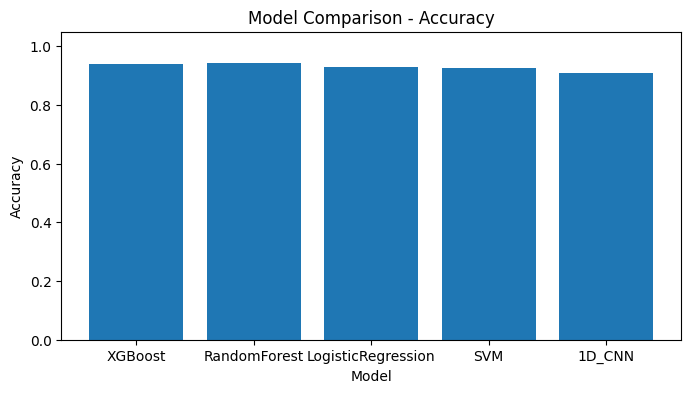

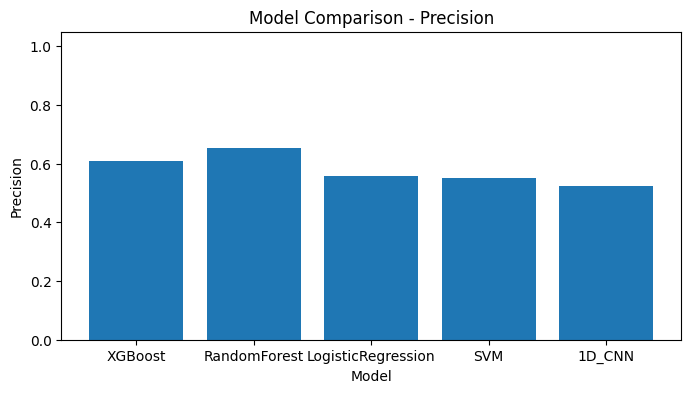

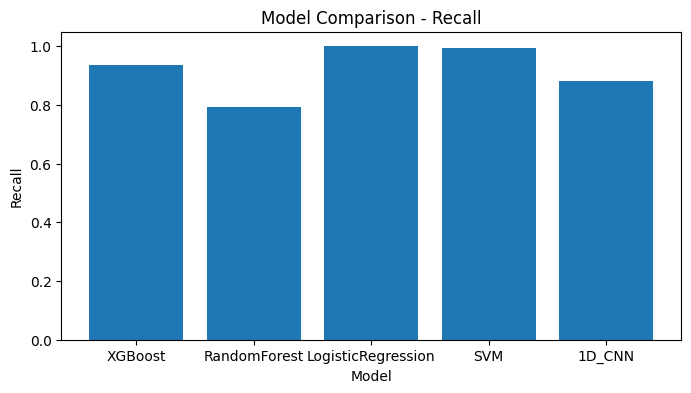

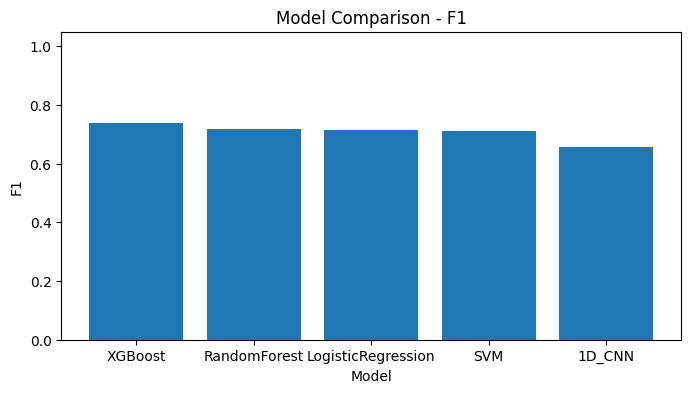

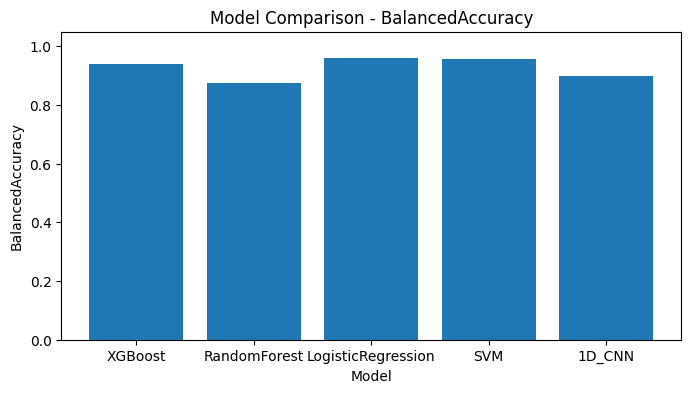

Kaydedildi: /content/all_model_results_ml_dl.csv


In [33]:
# ============================================================
# PART 15 — ML + Deep Learning Tek Blok Değerlendirme
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, callbacks
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

# ------------------------------------------------------------
# 1D CNN model tanımı
# ------------------------------------------------------------
def build_1d_cnn(input_shape):
    model = tf.keras.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv1D(32, kernel_size=7, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(64, kernel_size=5, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(128, kernel_size=3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(128, kernel_size=3, padding="same", activation="relu"),
        layers.GlobalAveragePooling1D(),

        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),

        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model


# ------------------------------------------------------------
# Sonuçları toplayacağımız listeler
# ------------------------------------------------------------
results = []
all_predictions = {}

# ------------------------------------------------------------
# 1) Klasik makine öğrenmesi modelleri
# ------------------------------------------------------------
print("=" * 80)
print("MAKINE ÖĞRENMESI MODELLERI")
print("=" * 80)

gkf_ml = GroupKFold(n_splits=5)

for model_name, model in ml_models.items():
    print("\n" + "=" * 70)
    print(f"MODEL: {model_name}")
    print("=" * 70)

    y_pred = cross_val_predict(
        model,
        X,
        y,
        cv=gkf_ml.split(X, y, groups=groups),
        n_jobs=-1
    )

    acc = accuracy_score(y, y_pred)
    prec = precision_score(y, y_pred, zero_division=0)
    rec = recall_score(y, y_pred, zero_division=0)
    f1 = f1_score(y, y_pred, zero_division=0)
    bacc = balanced_accuracy_score(y, y_pred)

    cm = confusion_matrix(y, y_pred)
    tn, fp, fn, tp = cm.ravel()

    results.append({
        "Model": model_name,
        "Type": "Machine Learning",
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1": f1,
        "BalancedAccuracy": bacc,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

    all_predictions[model_name] = y_pred

    print("Classification Report:")
    print(classification_report(y, y_pred, target_names=["Poor", "Good"]))

    print("Confusion Matrix:")
    print(cm)

    print("\nÖzet Metrikler:")
    print(f"Accuracy          : {acc:.4f}")
    print(f"Precision (Good)  : {prec:.4f}")
    print(f"Recall (Good)     : {rec:.4f}")
    print(f"F1-score (Good)   : {f1:.4f}")
    print(f"Balanced Accuracy : {bacc:.4f}")
    print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")


# ------------------------------------------------------------
# 2) 1D CNN derin öğrenme modeli
# ------------------------------------------------------------
print("\n" + "=" * 80)
print("DERIN ÖĞRENME MODELI: 1D CNN")
print("=" * 80)

# CNN class_weight
neg_count_cnn = int((y_cnn == 0).sum())
pos_count_cnn = int((y_cnn == 1).sum())
total_cnn = len(y_cnn)

class_weight_cnn = {
    0: total_cnn / (2 * neg_count_cnn),
    1: total_cnn / (2 * pos_count_cnn)
}

print("CNN class_weight:", class_weight_cnn)

gkf_cnn = GroupKFold(n_splits=3)

y_true_all = []
y_pred_all = []

fold_no = 1

for train_idx, test_idx in gkf_cnn.split(X_cnn, y_cnn, groups=groups_cnn):
    print("\n" + "=" * 70)
    print(f"1D CNN - Fold {fold_no}")
    print("=" * 70)

    X_train, X_test = X_cnn[train_idx], X_cnn[test_idx]
    y_train, y_test = y_cnn[train_idx], y_cnn[test_idx]

    cnn_model = build_1d_cnn((WINDOW, 1))

    early_stop = callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    cnn_model.fit(
        X_train, y_train,
        validation_split=0.2,
        epochs=25,
        batch_size=64,
        class_weight=class_weight_cnn,
        callbacks=[early_stop],
        verbose=1
    )

    y_prob = cnn_model.predict(X_test, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    y_true_all.extend(y_test.tolist())
    y_pred_all.extend(y_pred.tolist())

    print("Fold Classification Report:")
    print(classification_report(y_test, y_pred, target_names=["Poor", "Good"]))

    print("Fold Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    fold_no += 1

y_true_all = np.array(y_true_all)
y_pred_all = np.array(y_pred_all)

cnn_acc = accuracy_score(y_true_all, y_pred_all)
cnn_prec = precision_score(y_true_all, y_pred_all, zero_division=0)
cnn_rec = recall_score(y_true_all, y_pred_all, zero_division=0)
cnn_f1 = f1_score(y_true_all, y_pred_all, zero_division=0)
cnn_bacc = balanced_accuracy_score(y_true_all, y_pred_all)
cnn_cm = confusion_matrix(y_true_all, y_pred_all)

tn, fp, fn, tp = cnn_cm.ravel()

results.append({
    "Model": "1D_CNN",
    "Type": "Deep Learning",
    "Accuracy": cnn_acc,
    "Precision": cnn_prec,
    "Recall": cnn_rec,
    "F1": cnn_f1,
    "BalancedAccuracy": cnn_bacc,
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp
})

print("\n" + "=" * 70)
print("1D CNN OVERALL RESULTS")
print("=" * 70)
print(classification_report(y_true_all, y_pred_all, target_names=["Poor", "Good"]))
print("Confusion Matrix:")
print(cnn_cm)

print("\nÖzet Metrikler:")
print(f"Accuracy          : {cnn_acc:.4f}")
print(f"Precision (Good)  : {cnn_prec:.4f}")
print(f"Recall (Good)     : {cnn_rec:.4f}")
print(f"F1-score (Good)   : {cnn_f1:.4f}")
print(f"Balanced Accuracy : {cnn_bacc:.4f}")
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")


# ------------------------------------------------------------
# 3) Tüm modelleri aynı tabloda göster
# ------------------------------------------------------------
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="F1", ascending=False).reset_index(drop=True)

print("\n" + "=" * 80)
print("TÜM MODELLERİN KARŞILAŞTIRMA TABLOSU")
print("=" * 80)
display(results_df)


# ------------------------------------------------------------
# 4) Grafikler
# ------------------------------------------------------------
import matplotlib.pyplot as plt

metric_cols = ["Accuracy", "Precision", "Recall", "F1", "BalancedAccuracy"]

for metric in metric_cols:
    plt.figure(figsize=(8, 4))
    plt.bar(results_df["Model"], results_df[metric])
    plt.title(f"Model Comparison - {metric}")
    plt.xlabel("Model")
    plt.ylabel(metric)
    plt.ylim(0, 1.05)
    plt.xticks(rotation=0)
    plt.show()


# ------------------------------------------------------------
# 5) Kaydet
# ------------------------------------------------------------
results_df.to_csv("/content/all_model_results_ml_dl.csv", index=False)
print("Kaydedildi: /content/all_model_results_ml_dl.csv")